# Mouse fibroblast/decidual pseudotime from the final object

Input: the final fibroblast/decidual object. Output: the same object with `obs['pseudotime']`. The procedure is the harmonized time-informed diffusion pseudotime of the Methods (section "Pseudotime"), the same for both species:

1. Couplings between consecutive timepoints with moscot (unbalanced entropic optimal transport in the stromal scVI latent).
2. A CellRank RealTimeKernel combining the couplings with a same-day neighbor graph.
3. A 15-component diffusion map of the symmetrized transition matrix.
4. The root: the earliest-timepoint fibroblast at the fibroblast end of DC1.
5. DPT on all 15 components, rank-normalized.

The code of steps 1 to 5 is that of the runs of record (`harmonized_pseudotime.py`, sha256 `d4b618ae…`; mouse run of 22 Oct 2026, human run of 30 Oct 2026). Variable names are kept so the two can be compared line by line. Only the label and timepoint names were updated to the v9 vocabulary of the final objects.

**Nuclei.** The object holds the 43,197 mouse fibroblast and decidual nuclei. The 907 apoptotic decidual nuclei (`cell_subtype == "decAp"`) are excluded before anything is computed, as in the Methods. They stay in the output object with no pseudotime (`NaN`). Pseudotime is computed on the other 42,290 nuclei.

**Embedding.** The pseudotime runs on the 30-dimensional stromal scVI latent and its 3,000 highly variable genes. In the mouse final object these are `obsm['X_scVI']` and `var['highly_variable']`; both were checked on 6 Nov 2026 to be exactly the latent of record (`data/interim/latent_mouse_stromal.h5ad`).


**Running it.** Run it on the cluster with the `rsc_uv` environment, which has the package versions of the runs of record. Use 8 or more CPUs and about 100 GB of memory; the pseudotime takes about 5 minutes after loading. The notebook reads `INPUT_OBJECT` and writes only `OUTPUT_OBJECT`. Parameters can be set in the next cell or with papermill:

```
papermill pseudotime_mouse.ipynb pseudotime_mouse.executed.ipynb -p OUTPUT_OBJECT /path/to/out.h5ad
```

**Output.** A copy of the input object with:

- `obs['pseudotime']`: rank-normalized DPT (average rank / N), 0 at the root and 1 at the end;
- `obsm['X_diffmap']`: the 15 diffusion components, where column 0 is the trivial component and columns 1 and 2 are DC1 and DC2;
- `uns['pseudotime']`: the root, parameters, latent source and versions.

These replace the fields of the same name in the input. The last section compares them with the input's values, which are the run of record.

In [1]:
# Parameters (papermill can override these)
INPUT_OBJECT = "/n/netscratch/eddy_lab/Everyone/nhilgert/final_objects/Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"
INPUT_OBJECT = "mouse_fibs_final.h5ad"
OUTPUT_OBJECT = "/n/netscratch/eddy_lab/Everyone/nhilgert/2026_11_06_pseudotime_notebooks/Cevrim_XMens_Only_Fib_Dec_Cells_pseudotime.h5ad"

## Setup

The package versions are compared with those of the runs of record. Optimal transport and the eigensolver are floating-point computations, so identical results need identical versions, and in human also the same hardware (see the last section).

In [2]:
import datetime
import hashlib
import os
import time
import warnings
from importlib.metadata import version as pkg_version

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.sparse import csr_matrix
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")   # as in the runs of record: moscot, CellRank and scanpy warnings are left out

RECORD_VERSIONS = {"scanpy": "1.11.5", "anndata": "0.12.11", "cellrank": "2.0.7", "moscot": "0.5.0",
                   "ott-jax": "0.6.0", "jax": "0.10.0", "numpy": "2.2.0", "scipy": "1.17.1"}
versions = {p: pkg_version(p) for p in RECORD_VERSIONS}
for p, v in versions.items():
    print(f"{p:9s} {v}" + ("" if v == RECORD_VERSIONS[p] else f"   <-- runs of record used {RECORD_VERSIONS[p]}"))

P = dict(epsilon=1e-3, tau=0.95, scale_cost="mean", self_transitions="all", conn_weight=0.2, threshold="auto",
         n_neighbors=15, n_comps=15, n_dcs=15, seed=0)


def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 24), b""):
            digest.update(block)
    return digest.hexdigest()

scanpy    1.11.5
anndata   0.12.11
cellrank  2.0.7
moscot    0.5.0
ott-jax   0.6.0
jax       0.10.0
numpy     2.2.0
scipy     1.17.1


In [10]:
LABEL_COL = "cell_subtype"
EXCLUDE = {"cell_subtype": ["decAp"]}           # apoptotic decidual nuclei: no pseudotime (Methods)

In [34]:
N_EXCLUDED = 907
DAY = {"uninduced": 0.0, "1.5dpi_early": 1.0, "1.5dpi_late": 1.5, "2.5dpi": 2.0, "3.5dpi": 3.0,
       "4.5dpi_menstrual": 4.0}
# Fibroblast -> decidual order used only to orient the trajectory component and pick the root's end.
ORDER = ["eFib1", "eFib2", "eFib2i", "eFib3", "eFibP", "dec1", "dec2", "dec3"]
is_fibroblast = lambda labels: labels.str.startswith("eFib")
GENE_SET = "mouse"                               # moscot's proliferation and apoptosis gene sets
RECORD_ROOT = "ACCCTTGAGCATGAAT-1-uninduced_mck8b"

In [35]:
obj.obs['timepoint']

CATACAGCACCTCTAC-1-uninduced_mck8a                 uninduced
TTTATGCCATACATCG-1-uninduced_mck8a                 uninduced
AGTTCCCCAATCCTTT-1-uninduced_mck8a                 uninduced
TAATTCCCACAAGCCC-1-uninduced_mck8a                 uninduced
AACAAAGCAATTTCCT-1-uninduced_mck8a                 uninduced
                                                  ...       
CCTATCGTCAAGCCCG-1-4_dpi_bleeding_mck11a    4.5dpi_menstrual
TGGGAAGAGCGACAGT-1-4_dpi_bleeding_mck11a    4.5dpi_menstrual
GTCGCGAGTCGAGTTT-1-4_dpi_bleeding_mck11a    4.5dpi_menstrual
TCATATCAGGCATCTT-1-4_dpi_bleeding_mck11a    4.5dpi_menstrual
TTCCGGTGTAAGGTCG-1-4_dpi_bleeding_mck11a    4.5dpi_menstrual
Name: timepoint, Length: 42966, dtype: category
Categories (6, object): ['uninduced', '1.5dpi_early', '1.5dpi_late', '2.5dpi', '3.5dpi', '4.5dpi_menstrual']

## The object

The labels and timepoints are checked against the vocabulary above, so that a renamed category fails here and not silently later.

In [3]:
t_start = time.time()
obj = sc.read_h5ad(INPUT_OBJECT)
input_sha256 = sha256_of(INPUT_OBJECT)

In [4]:
print(f"{INPUT_OBJECT}: {obj.n_obs:,} nuclei x {obj.n_vars:,} genes (sha256 {input_sha256[:12]}...)")

mouse_fibs_final.h5ad: 42,966 nuclei x 32,287 genes (sha256 70e42b53ceb7...)


In [36]:
#assert obj.n_obs == 43197, obj.n_obs
assert set(obj.obs["timepoint"].astype(str)) == set(DAY), sorted(set(obj.obs["timepoint"].astype(str)))
labels_present = set(obj.obs[LABEL_COL].astype(str))
excluded_labels = {v for values in EXCLUDE.values() for v in values}
assert labels_present == set(ORDER) | excluded_labels, sorted(labels_present)

# The input's own pseudotime and diffusion map (the run of record), kept for the comparison at the end
stored_pseudotime = obj.obs["pseudotime"].copy() if "pseudotime" in obj.obs else None
stored_diffmap = np.asarray(obj.obsm["X_diffmap"]).copy() if "X_diffmap" in obj.obsm else None

## Embedding

The stromal scVI latent of record is stored in the object, so it is used as is. This notebook does not refit it. Refitting scVI on a GPU reproduces only within one GPU class, and the mouse latent of record was fit in July 2026.

In [14]:
latent = np.asarray(obj.obsm["X_scVI"])
hvg_genes = obj.var_names[obj.var["highly_variable"].astype(bool).to_numpy()]
latent_source = "obsm['X_scVI'] of the input object (stromal latent of record, latent_mouse_stromal.h5ad)"
assert latent.shape == (obj.n_obs, 30) and len(hvg_genes) == 3000, (latent.shape, len(hvg_genes))
print(f"latent {latent.shape[1]} dimensions; {len(hvg_genes)} highly variable genes")

latent 30 dimensions; 3000 highly variable genes


In [31]:
obj

AnnData object with n_obs × n_vars = 42966 × 32287
    obs: 'sample', 'timepoint', 'n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'pct_counts_ribo', 'doubletdetection_predicted_doublet', 'doubletdetection_doublet_score', 'cell_barcode', 'x_um_dbscan', 'y_um_dbscan', 'cell_type', 'cell_subtype'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'cell_subtype_colors', 'cell_type_colors', 'hvg', 'neighbors_scVI_100', 'sample_colors', 'timepoint_colors', 'umap'
    obsm: 'X_scVI', 'X_umap_scVI', 'spatial'
    layers: 'log1p_counts', 'raw_counts'
    obsp: 'neighbors_scVI_100_connectivities', 'neighbors_scVI_100_distances'

In [33]:
obj

AnnData object with n_obs × n_vars = 42966 × 32287
    obs: 'sample', 'timepoint', 'n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'pct_counts_ribo', 'doubletdetection_predicted_doublet', 'doubletdetection_doublet_score', 'cell_barcode', 'x_um_dbscan', 'y_um_dbscan', 'cell_type', 'cell_subtype'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'cell_subtype_colors', 'cell_type_colors', 'hvg', 'neighbors_scVI_100', 'sample_colors', 'timepoint_colors', 'umap'
    obsm: 'X_scVI', 'X_umap_scVI', 'spatial'
    layers: 'log1p_counts', 'raw_counts'
    obsp: 'neighbors_scVI_100_connectivities', 'neighbors_scVI_100_distances'

In [5]:
obj_noap = obj[obj.obs['cell_subtype'] != 'decAp'].copy()

In [7]:
obj_noap

AnnData object with n_obs × n_vars = 41811 × 32287
    obs: 'sample', 'timepoint', 'n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'pct_counts_ribo', 'doubletdetection_predicted_doublet', 'doubletdetection_doublet_score', 'cell_barcode', 'x_um_dbscan', 'y_um_dbscan', 'cell_type', 'cell_subtype'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'cell_subtype_colors', 'cell_type_colors', 'hvg', 'neighbors_scVI_100', 'sample_colors', 'timepoint_colors', 'umap'
    obsm: 'X_scVI', 'X_umap_scVI', 'spatial'
    layers: 'log1p_counts', 'raw_counts'
    obsp: 'neighbors_scVI_100_connectivities', 'neighbors_scVI_100_distances'

In [ ]:
# New scVI embedding with the settings of record (workflow/scripts/atlas/reintegrate.py; Methods):
# raw counts; mitochondrial and ribosomal genes removed; genes detected in fewer than 3 nuclei removed;
# 3,000 highly variable genes (seurat_v3) selected on the pooled nuclei (no batch key: per-sample fits are unstable
# in small groups); scVI with 30 latent dimensions, 2 layers, negative-binomial likelihood, batch key "sample",
# seed 0, early stopping. Fit on every nucleus of the object (in mouse the latent of record includes the 907 decAp).
# Needs a GPU in practice (~10 min on an A40; scVI reproduces exactly only within one GPU class).
import scvi
import torch

adata = obj_noap                                  # the object you just loaded
COUNTS_LAYER = "raw_counts"
SEED = 0

counts = adata.layers[COUNTS_LAYER]
sample_block = counts[:200].toarray() if hasattr(counts, "toarray") else np.asarray(counts[:200])
assert np.allclose(sample_block, np.round(sample_block)), f"layers['{COUNTS_LAYER}'] does not look like raw counts"

scvi.settings.seed = SEED
np.random.seed(SEED)

fit = ad.AnnData(X=counts.copy(), obs=adata.obs[["sample"]].copy(), var=pd.DataFrame(index=adata.var_names))
fit.layers["counts"] = fit.X.copy()
mito = fit.var_names.str.startswith(("mt-", "Mt-", "MT-"))
ribo = fit.var_names.str.startswith(("rps", "rpl", "mrps", "mrpl", "Rps", "Rpl", "Mrps", "Mrpl",
                                     "RPS", "RPL", "MRPS", "MRPL"))
fit_hvg = fit[:, (~mito) & (~ribo)].copy()
sc.pp.filter_genes(fit_hvg, min_cells=3)
sc.pp.highly_variable_genes(fit_hvg, flavor="seurat_v3", layer="counts", n_top_genes=3000, subset=True)
print(f"{adata.n_obs:,} nuclei; mito {int(mito.sum())}, ribo {int(ribo.sum())} excluded; "
      f"{fit_hvg.n_vars} highly variable genes; GPU: "
      f"{torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none (CPU: slow)'}")

scvi.model.SCVI.setup_anndata(fit_hvg, layer="counts", batch_key="sample")
model = scvi.model.SCVI(fit_hvg, n_layers=2, n_latent=30, gene_likelihood="nb")
model.train(early_stopping=True)

In [41]:
# Where the pseudotime steps read the embedding
adata.obsm["X_scVI"] = np.asarray(model.get_latent_representation(), dtype=np.float32)
adata.var["highly_variable"] = adata.var_names.isin(fit_hvg.var_names)
print(f"X_scVI {adata.obsm['X_scVI'].shape}; {int(adata.var['highly_variable'].sum())} highly variable genes flagged")

# The same-day neighbor graph uses a PCA of log-normalized .X; make sure .X is not raw counts
x_block = adata.X[:200].toarray() if hasattr(adata.X, "toarray") else np.asarray(adata.X[:200])
if np.allclose(x_block, np.round(x_block)):
    print("Note: .X looks like raw counts; log-normalize it (normalize_total 1e4, log1p) before computing pseudotime.")

X_scVI (41811, 30); 3000 highly variable genes flagged
Note: .X looks like raw counts; log-normalize it (normalize_total 1e4, log1p) before computing pseudotime.


## Nuclei of the run, timepoints as days, and the working object

The working object `a` holds only what the computation reads: log-normalized expression `.X` (for the same-day PCA graph), the labels, timepoints and samples, the highly variable genes, and the latent as `obsm['X_scVI']`. Fields the input carries from earlier runs (for example `X_diffmap`) are therefore not seen by the steps below.

In [42]:
obj = adata.copy()

In [43]:
keep = np.ones(obj.n_obs, dtype=bool)
for col, values in EXCLUDE.items():
    keep &= ~obj.obs[col].astype(str).isin(values).to_numpy()
#assert int((~keep).sum()) == N_EXCLUDED, int((~keep).sum())

In [45]:
keep

array([ True,  True,  True, ...,  True,  True,  True], shape=(41811,))

In [46]:
latent = adata.obsm['X_scVI'].copy()

In [47]:
a = ad.AnnData(X=obj.X[keep].copy(),
               obs=obj.obs.loc[keep, [LABEL_COL, "timepoint", "sample"]].astype(str),
               var=pd.DataFrame(index=obj.var_names))
a.var["highly_variable"] = a.var_names.isin(hvg_genes)       # used by the PCA behind the same-day graph
a.obsm["X_scVI"] = latent[keep]
a.obs["day"] = a.obs.timepoint.map(DAY).astype(float).astype("category")
assert int(a.var.highly_variable.sum()) == 3000
print(f"{obj.n_obs:,} nuclei in the object, {a.n_obs:,} in the run ({N_EXCLUDED} excluded)")
#assert a.n_obs == 42290

41,811 nuclei in the object, 41,811 in the run (907 excluded)


## Step 1. Couplings between consecutive timepoints (moscot)

Squared Euclidean cost in the 30-dimensional latent, scaled by its mean; ε = 10⁻³; τa = τb = 0.95; prior growth rates from moscot's proliferation and apoptosis gene sets.

In [48]:
from moscot.problems.time import TemporalProblem
import jax

tp = TemporalProblem(a).score_genes_for_marginals(gene_set_proliferation=GENE_SET, gene_set_apoptosis=GENE_SET)
tp = tp.prepare(time_key="day", joint_attr="X_scVI")
tp = tp.solve(epsilon=P["epsilon"], tau_a=P["tau"], tau_b=P["tau"], scale_cost=P["scale_cost"])
converged = {str(k): bool(pr.solution.converged) for k, pr in tp.problems.items()}
print(f"moscot on {jax.default_backend()}: {len(converged)} coupling(s), all converged = {all(converged.values())}")
assert all(converged.values())

INFO     Solving `5` problems                                                                                      
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(9309, 2681)].                                  
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(10312, 5450)].                                 
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(2681, 10606)].                                 
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(3453, 10312)].                                 
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(10606, 3453)].                                 
moscot on gpu: 5 coupling(s), all converged = True


## Step 2. CellRank RealTimeKernel

These are the kernel settings of the CellRank protocol: `self_transitions="all"`, `conn_weight=0.2`, `threshold="auto"`. The same-day neighbor graph has 15 neighbors. It is built the scanpy default way, on a 50-component PCA of `.X` restricted to the 3,000 highly variable genes. The row repair is never triggered (0 repaired rows in both runs of record); it is kept so the code matches the script of record.

In [54]:
import cellrank as cr

conn_kwargs = {"n_neighbors": P["n_neighbors"]}                    # no use_rep: the PCA graph of the runs of record
rtk = cr.kernels.RealTimeKernel.from_moscot(tp)
n_dead = 0
try:
    rtk = rtk.compute_transition_matrix(self_transitions=P["self_transitions"], conn_weight=P["conn_weight"],
                                        threshold=P["threshold"], conn_kwargs=conn_kwargs)
except ValueError as e:
    # CellRank rejects a matrix whose rows do not sum to 1; same within-day uniform repair as the released notebooks.
    if "row stochastic" not in str(e):
        raise
    T = csr_matrix(rtk._transition_matrix).tocsr()
    rs = np.asarray(T.sum(1)).ravel()
    dead = np.where(~np.isfinite(rs) | (rs == 0))[0]
    n_dead = len(dead)
    dv = a.obs.day.astype(float).to_numpy()
    L = T.tolil()
    for i in dead:
        same = np.where(dv == dv[i])[0]
        L.rows[i] = list(same)
        L.data[i] = [1.0 / len(same)] * len(same)
    T = L.tocsr()
    T = csr_matrix(T.multiply(1.0 / np.asarray(T.sum(1)).ravel()[:, None]))
    rtk.transition_matrix = T
T = rtk.transition_matrix
dv = a.obs.day.astype(float).to_numpy()
Tc = T.tocoo()
mass = {k: float(Tc.data[np.sign(dv[Tc.col] - dv[Tc.row]) == s].sum() / Tc.data.sum())
        for k, s in (("later", 1), ("same", 0), ("earlier", -1))}
print(f"transition matrix {T.shape}; mass later {mass['later']:.3f} / same {mass['same']:.3f} / "
      f"earlier {mass['earlier']:.3f}; repaired rows {n_dead}")

  0%|          | 0/5 [00:00<?, ?time pair/s]

/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 32287 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)
/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 32287 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)
/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 32287 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falli

ValueError: scipy.sparse does not support dtype object. The only supported types are: bool, int8, uint8, int16, uint16, int32, uint32, int64, uint64, longlong, ulonglong, float32, float64, longdouble, complex64, complex128, clongdouble.

In [51]:
import scipy.sparse as sp

# Per-row count of non-finite entries (works on the sparse matrix's stored values)
T_nonfinite = T0.copy()
T_nonfinite.data = (~np.isfinite(T0.data)).astype(np.float64)
row_nan = np.asarray(T_nonfinite.sum(1)).ravel()
row_sum = np.asarray(T0.sum(1)).ravel()
bad = np.where(~np.isfinite(row_sum) | (row_sum == 0) | (row_nan > 0))[0]
print(f"{len(bad)} invalid rows")
report = a.obs.iloc[bad][[LABEL_COL, "timepoint", "sample", "day"]].copy()
report["row_sum"], report["n_nonzero"], report["n_nan"] = row_sum[bad], np.diff(T0.indptr)[bad], row_nan[bad]
print(report)

# Likely culprits behind an empty or NaN row
X_hvg = a[:, a.var.highly_variable.to_numpy()].X
x_values = X_hvg.data if sp.issparse(X_hvg) else np.asarray(X_hvg)
hvg_total = np.asarray(X_hvg.sum(1)).ravel()
print("NaN/inf in .X (HVGs):", int((~np.isfinite(x_values)).sum()))
print("NaN/inf in X_scVI:", int((~np.isfinite(a.obsm["X_scVI"])).sum()))
print("these nuclei: total HVG expression", hvg_total[bad])
print("nuclei with zero expression in all HVGs:", int((hvg_total == 0).sum()))
print("duplicate obs_names:", int(a.obs_names.duplicated().sum()))

5 invalid rows
                                     cell_subtype    timepoint  \
ACATCCCTCATACGGT-1-1_dpi_late_mck12b         dec3  1.5dpi_late   
CTTACCGCACCTCTGT-1-1_dpi_late_mck12b         dec1  1.5dpi_late   
AGGAAATTCGCCTATC-1-3_dpi_mck10b              dec3       3.5dpi   
GGGCTCATCTTCTCAA-1-3_dpi_mck10b              dec1       3.5dpi   
CCACCATGTAACCAGG-1-3_dpi_mck10b              dec3       3.5dpi   

                                                  sample  day  row_sum  \
ACATCCCTCATACGGT-1-1_dpi_late_mck12b  1.5dpi_late_mck12b  1.5      inf   
CTTACCGCACCTCTGT-1-1_dpi_late_mck12b  1.5dpi_late_mck12b  1.5      inf   
AGGAAATTCGCCTATC-1-3_dpi_mck10b            3.5dpi_mck10b  3.0      inf   
GGGCTCATCTTCTCAA-1-3_dpi_mck10b            3.5dpi_mck10b  3.0      inf   
CCACCATGTAACCAGG-1-3_dpi_mck10b            3.5dpi_mck10b  3.0      inf   

                                      n_nonzero  n_nan  
ACATCCCTCATACGGT-1-1_dpi_late_mck12b         16    1.0  
CTTACCGCACCTCTGT-1-1_dpi_late

In [52]:
# 5 nuclei whose transport row came out non-finite: drop the non-finite value and keep their same-day transitions
T = T0.copy()
nonfinite_rows = np.unique(np.repeat(np.arange(T.shape[0]), np.diff(T.indptr))[~np.isfinite(T.data)])
T.data[~np.isfinite(T.data)] = 0.0
T.eliminate_zeros()
rs = np.asarray(T.sum(1)).ravel()
dead = np.where(rs == 0)[0]                      # rows with nothing left: uniform within their timepoint
dv = a.obs.day.astype(float).to_numpy()
L = T.tolil()
for i in dead:
    same = np.where(dv == dv[i])[0]
    L.rows[i] = list(same)
    L.data[i] = [1.0 / len(same)] * len(same)
T = L.tocsr()
T = csr_matrix(T.multiply(1.0 / np.asarray(T.sum(1)).ravel()[:, None]))
rtk.transition_matrix = T
rtk._obs = tmap.obs
n_dead = len(nonfinite_rows) + len(np.setdiff1d(dead, nonfinite_rows))
print(f"{len(nonfinite_rows)} rows with a non-finite transport value kept their same-day transitions; "
      f"{len(dead)} rows set uniform within their timepoint; repaired rows {n_dead}")

5 rows with a non-finite transport value kept their same-day transitions; 0 rows set uniform within their timepoint; repaired rows 5


In [53]:
src_of = {1.5: (1.5, 2.0), 3.0: (3.0, 4.0)}
for i in bad:
    key = src_of[float(dv[i])]
    cpl = rtk.couplings[key]
    row = cpl[a.obs_names[i]].X
    row = row.toarray().ravel() if sp.issparse(row) else np.asarray(row).ravel()
    print(a.obs_names[i], key, cpl.X.dtype, "sum", row.sum(), "max", row.max(), "nonzero", int((row > 0).sum()))

ACATCCCTCATACGGT-1-1_dpi_late_mck12b (1.5, 2.0) float32 sum 1e-45 max 1e-45 nonzero 1
CTTACCGCACCTCTGT-1-1_dpi_late_mck12b (1.5, 2.0) float32 sum 5.68054e-40 max 5.68054e-40 nonzero 1
AGGAAATTCGCCTATC-1-3_dpi_mck10b (3.0, 4.0) float32 sum 2.13244e-40 max 2.13244e-40 nonzero 1
GGGCTCATCTTCTCAA-1-3_dpi_mck10b (3.0, 4.0) float32 sum 4e-45 max 4e-45 nonzero 1
CCACCATGTAACCAGG-1-3_dpi_mck10b (3.0, 4.0) float32 sum 3.8e-44 max 3.8e-44 nonzero 1


In [56]:
# Repair, install and summarize the transition matrix in one cell (uses T0 and tmap from the diagnosis cell)
assert "T0" in globals() and "tmap" in globals(), "run the diagnosis cell first (it builds tmap and T0)"
assert tmap.obs_names.equals(a.obs_names)

T = T0.copy()
nonfinite_rows = np.unique(np.repeat(np.arange(T.shape[0]), np.diff(T.indptr))[~np.isfinite(T.data)])
T.data[~np.isfinite(T.data)] = 0.0              # drop the non-finite transport value; same-day transitions remain
T.eliminate_zeros()
rs = np.asarray(T.sum(1)).ravel()
dead = np.where(rs == 0)[0]                      # rows with nothing left: uniform within their timepoint
dv = a.obs.day.astype(float).to_numpy()
L = T.tolil()
for i in dead:
    same = np.where(dv == dv[i])[0]
    L.rows[i] = list(same)
    L.data[i] = [1.0 / len(same)] * len(same)
T = L.tocsr()
T = csr_matrix(T.multiply(1.0 / np.asarray(T.sum(1)).ravel()[:, None]))
rtk.transition_matrix = T
rtk._obs = tmap.obs
n_dead = len(nonfinite_rows) + len(np.setdiff1d(dead, nonfinite_rows))

T = rtk.transition_matrix
assert T is not None and np.allclose(np.asarray(T.sum(1)).ravel(), 1.0)
Tc = T.tocoo()
mass = {k: float(Tc.data[np.sign(dv[Tc.col] - dv[Tc.row]) == s].sum() / Tc.data.sum())
        for k, s in (("later", 1), ("same", 0), ("earlier", -1))}
print(f"{len(nonfinite_rows)} rows kept same-day transitions only; {len(dead)} set uniform within their timepoint")
print(f"transition matrix {T.shape}; mass later {mass['later']:.3f} / same {mass['same']:.3f} / "
      f"earlier {mass['earlier']:.3f}; repaired rows {n_dead}")

5 rows kept same-day transitions only; 0 set uniform within their timepoint
transition matrix (41811, 41811); mass later 0.696 / same 0.304 / earlier 0.000; repaired rows 5


In [65]:
# Nuclei whose transport row underflowed (< float32 range): treat them like CellRank's exactly-empty coupling rows,
# i.e. keep their same-day transitions (weight conn_weight) and spread the forward part uniformly over the next timepoint.
assert "T0" in globals() and "tmap" in globals() and tmap.obs_names.equals(a.obs_names)
dv = a.obs.day.astype(float).to_numpy()
days = np.sort(np.unique(dv))
T = T0.copy()
nonfinite_rows = np.unique(np.repeat(np.arange(T.shape[0]), np.diff(T.indptr))[~np.isfinite(T.data)])
T.data[~np.isfinite(T.data)] = 0.0
T.eliminate_zeros()
same_day_sum = np.asarray(T.sum(1)).ravel()[nonfinite_rows]
print("same-day weight left in those rows (expect", P["conn_weight"], "):", np.round(same_day_sum, 6))
L = T.tolil()
for i in nonfinite_rows:
    targets = np.where(dv == days[np.searchsorted(days, dv[i]) + 1])[0]
    row = dict(zip(L.rows[i], L.data[i]))
    for j in targets:
        row[j] = row.get(j, 0.0) + (1 - P["conn_weight"]) / len(targets)
    cols = sorted(row)
    L.rows[i], L.data[i] = cols, [row[j] for j in cols]
T = L.tocsr()
T = csr_matrix(T.multiply(1.0 / np.asarray(T.sum(1)).ravel()[:, None]))
rtk.transition_matrix = T
rtk._obs = tmap.obs
n_dead = len(nonfinite_rows)

T = rtk.transition_matrix
assert T is not None and np.allclose(np.asarray(T.sum(1)).ravel(), 1.0)
Tc = T.tocoo()
mass = {k: float(Tc.data[np.sign(dv[Tc.col] - dv[Tc.row]) == s].sum() / Tc.data.sum())
        for k, s in (("later", 1), ("same", 0), ("earlier", -1))}
print(f"transition matrix {T.shape}; mass later {mass['later']:.3f} / same {mass['same']:.3f} / "
      f"earlier {mass['earlier']:.3f}; rows given uniform forward transitions {n_dead}")

same-day weight left in those rows (expect 0.2 ): [0.2 0.2 0.2 0.2 0.2]
transition matrix (41811, 41811); mass later 0.696 / same 0.304 / earlier 0.000; rows given uniform forward transitions 5


## Step 3. Diffusion map of the symmetrized transition matrix

(T + Tᵀ)/2 with rows renormalized, then the 15 leading eigenvectors, seed 0 (Weiler et al. 2024). Scanpy's `DPT` object needs a neighbor graph to be built, so one is computed on the latent. Its transitions are then replaced by the symmetrized matrix, and the graph itself is not used.

In [66]:
from scanpy.tools._dpt import DPT

S = (T + T.T) / 2
rs = S.sum(axis=1).A1
S.data = S.data / rs[S.nonzero()[0]]
sc.pp.neighbors(a, use_rep="X_scVI", n_neighbors=P["n_neighbors"], random_state=P["seed"])   # required by DPT(); not used
dpt = DPT(adata=a, neighbors_key="neighbors")
dpt._transitions_sym = S
dpt.compute_eigen(n_comps=P["n_comps"], random_state=P["seed"])
a.obsm["X_diffmap"] = dpt.eigen_basis
a.uns["diffmap_evals"] = dpt.eigen_values
DM = np.asarray(a.obsm["X_diffmap"])

## Step 4. Root

The trajectory component is the diffusion component (DC1 to DC5) most correlated with the fibroblast-to-decidual order; it is DC1 in both species. The root is the earliest-timepoint fibroblast at the fibroblast end of that component.

In [67]:
lab = a.obs[LABEL_COL]
order_rank = lab.map({s: i for i, s in enumerate(ORDER)}).to_numpy(float)
assert np.isfinite(order_rank).all(), sorted(set(lab[~np.isfinite(order_rank)]))
rhos = {i: float(spearmanr(DM[:, i], order_rank).statistic) for i in range(1, 6)}
best = max(rhos, key=lambda i: abs(rhos[i]))
fib_end = "max" if rhos[best] < 0 else "min"       # fibroblasts come first in the order, so they sit at the opposite sign
pool = (is_fibroblast(lab) & (a.obs.day.astype(float) == a.obs.day.astype(float).min())).to_numpy()
v = np.where(pool, DM[:, best], np.nan)
root = int(np.nanargmax(v) if fib_end == "max" else np.nanargmin(v))
global_extreme = int(np.argmax(DM[:, best]) if fib_end == "max" else np.argmin(DM[:, best]))
print(f"trajectory component DC{best} (rho {rhos[best]:+.3f}); root {a.obs_names[root]} ({lab.iloc[root]}); "
      f"global extreme {'same cell' if root == global_extreme else a.obs_names[global_extreme]}")

trajectory component DC1 (rho -0.872); root CTAACCCGTCAACGCC-1-uninduced_mck8b (eFib1); global extreme same cell


## Step 5. DPT and rank normalization

`scanpy.tl.dpt` on all 15 components of the diffusion map above, rank-normalized as average rank / N over the nuclei of the run.

In [68]:
a.uns["iroot"] = root
sc.tl.dpt(a, n_dcs=P["n_dcs"])
pt = a.obs["dpt_pseudotime"].to_numpy(float)
assert np.isfinite(pt).all() and pt[root] == 0
pt_rank = pd.Series(pt).rank(pct=True).to_numpy()
rho_day = float(spearmanr(pt_rank, a.obs.day.astype(float)).statistic)
print(f"pseudotime on {a.n_obs:,} nuclei; root {a.obs_names[root]}; Spearman rho with timepoint {rho_day:.2f}")

pseudotime on 41,811 nuclei; root CTAACCCGTCAACGCC-1-uninduced_mck8b; Spearman rho with timepoint 0.70


## Output object

A copy of the input object, with the pseudotime, the diffusion map and a record of the run. Excluded nuclei, if any, get `NaN`.

/tmp/ipykernel_3841032/1959952000.py:55: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


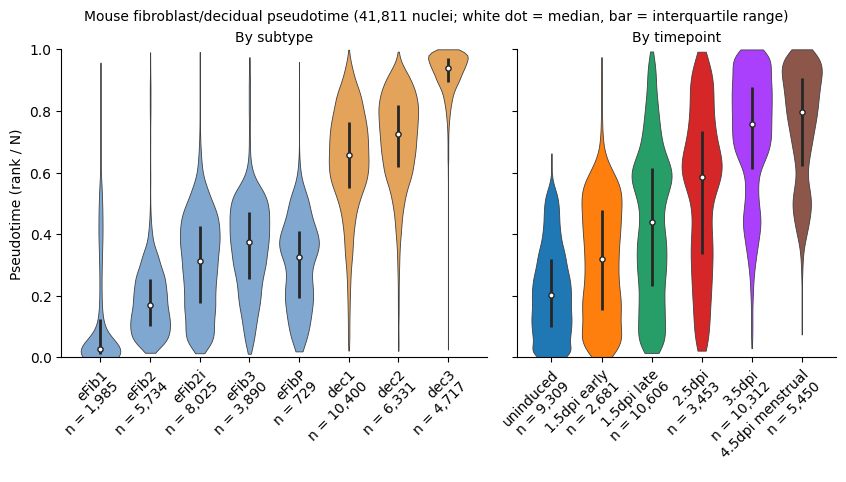

In [71]:
# Violin plots of the rank-normalized pseudotime, by subtype and by timepoint.
# Nuclei without a pseudotime (the 907 decAp) are left out.
# For coarse cell types instead of subtypes, set GROUP_COL = "cell_type" (groups are then ordered by median pseudotime).
import matplotlib.pyplot as plt

GROUP_COL = LABEL_COL                       # "cell_subtype"

cells = out.obs.loc[out.obs["pseudotime"].notna(), ["pseudotime", GROUP_COL, "timepoint"]].astype(
    {GROUP_COL: str, "timepoint": str})
group_order = ORDER if GROUP_COL == LABEL_COL else list(
    cells.groupby(GROUP_COL)["pseudotime"].median().sort_values().index)
timepoint_order = sorted(DAY, key=DAY.get)

# Timepoint colors from the object when it carries them (scanpy stores them in category order)
tp_categories = list(out.obs["timepoint"].cat.categories) if hasattr(out.obs["timepoint"], "cat") else []
tp_colors = dict(zip(tp_categories, out.uns.get("timepoint_colors", [])))
FIB_COLOR, DEC_COLOR, OTHER_COLOR = "#7fa7cf", "#e3a35b", "#bdbdbd"


def group_color(group):
    if group.lower().startswith(("efib", "endometrial_fib", "fib")):
        return FIB_COLOR
    if group.lower().startswith(("dec", "decidual")):
        return DEC_COLOR
    return OTHER_COLOR


def draw_violins(ax, column, order, colors):
    values = [cells.loc[cells[column] == group, "pseudotime"].to_numpy() for group in order]
    positions = np.arange(1, len(order) + 1)
    parts = ax.violinplot(values, positions=positions, widths=0.8, showextrema=False)
    for body, color in zip(parts["bodies"], colors):
        body.set_facecolor(color)
        body.set_edgecolor("0.25")
        body.set_linewidth(0.6)
        body.set_alpha(1)
    quartiles = np.array([np.percentile(v, [25, 50, 75]) for v in values])
    ax.vlines(positions, quartiles[:, 0], quartiles[:, 2], color="0.15", linewidth=2)
    ax.scatter(positions, quartiles[:, 1], color="white", edgecolor="0.15", s=14, zorder=3)
    labels = [f"{group.replace('_', ' ')}\nn = {len(v):,}" for group, v in zip(order, values)]
    ax.set_xticks(positions, labels, rotation=45, ha="right", rotation_mode="anchor")
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True,
                         gridspec_kw={"width_ratios": [len(group_order), len(timepoint_order)], "wspace": 0.08})
draw_violins(axes[0], GROUP_COL, group_order, [group_color(g) for g in group_order])
draw_violins(axes[1], "timepoint", timepoint_order, [tp_colors.get(t, OTHER_COLOR) for t in timepoint_order])
axes[0].set_title("By subtype" if GROUP_COL == LABEL_COL else "By cell type", fontsize=10)
axes[1].set_title("By timepoint", fontsize=10)
axes[0].set_ylabel("Pseudotime (rank / N)")
axes[0].set_ylim(0, 1)
fig.suptitle(f"Mouse fibroblast/decidual pseudotime ({len(cells):,} nuclei; white dot = median, bar = interquartile range)",
             fontsize=10)
fig.tight_layout()
plt.show()

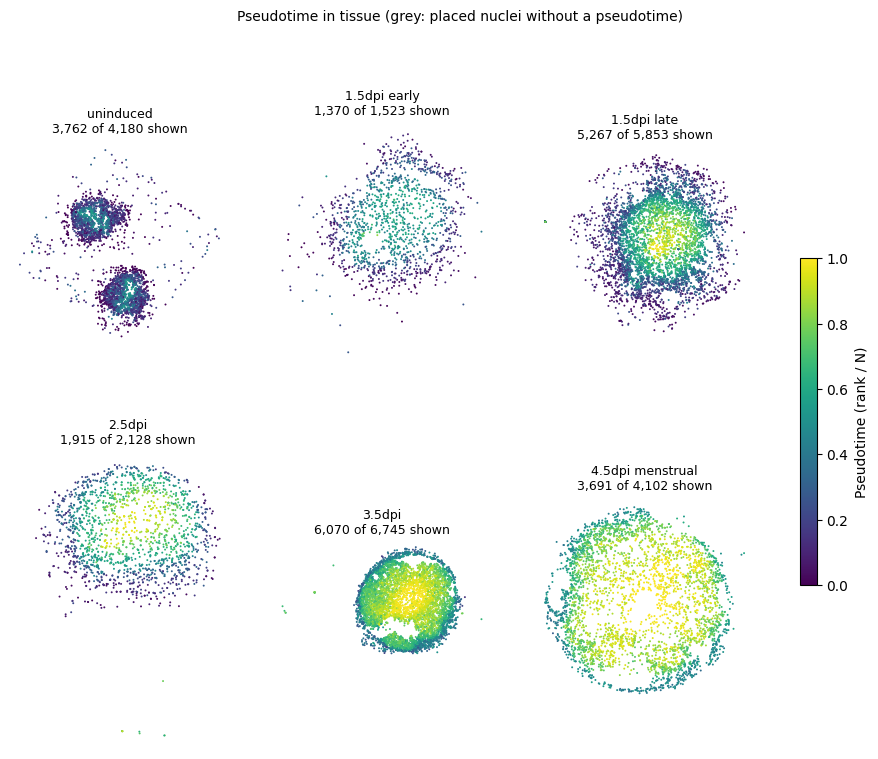

In [72]:
# Spatial pseudotime: one panel per timepoint (the 10x lanes of a timepoint are sections of one tissue in one
# coordinate frame, so they are pooled, as in the paper's spatial figures). Reads `out` and `DAY` from the notebook.
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

FILTER_DISCORDANT = True     # Methods: omit for display the 10% of nuclei whose pseudotime differs most from the
                             # median of their 5 nearest spatial neighbors, within each section
ROTATE = True                # Methods: sections rotated rigidly about the median position of their plotted nuclei
timepoint_order = sorted(DAY, key=DAY.get)
# Degrees counter-clockwise, uninduced -> 4.5 dpi bleeding (resources/figures/mouse_section_rotation.yaml)
ROTATION_DEG = dict(zip(timepoint_order, [322.75, 28.0, 303.0, 175.0, 135.0, 81.0]))

if {"x_um_dbscan", "y_um_dbscan"} <= set(out.obs.columns):
    xy = out.obs[["x_um_dbscan", "y_um_dbscan"]].to_numpy(float)    # QC'd positions (NaN where blanked)
else:
    xy = np.asarray(out.obsm["X_spatial"], dtype=float)
pt_all = out.obs["pseudotime"].to_numpy(float)
tp_all = out.obs["timepoint"].astype(str).to_numpy()
placed = np.isfinite(xy).all(axis=1)
rng = np.random.default_rng(0)

fig, axes = plt.subplots(2, 3, figsize=(12, 8.5))
for ax, tp in zip(axes.ravel(), timepoint_order):
    in_tp = (tp_all == tp) & placed
    with_pt = in_tp & np.isfinite(pt_all)
    pts, vals = xy[with_pt], pt_all[with_pt]
    background = xy[in_tp & ~np.isfinite(pt_all)]          # placed nuclei without a pseudotime (decAp)
    n_with_pt = len(vals)
    if FILTER_DISCORDANT and len(vals) > 5:
        _, neighbors = cKDTree(pts).query(pts, k=6)           # each nucleus and its 5 nearest neighbors
        discordance = np.abs(vals - np.median(vals[neighbors[:, 1:]], axis=1))
        keep = discordance <= np.quantile(discordance, 0.9)
        pts, vals = pts[keep], vals[keep]
    if ROTATE:
        theta = np.deg2rad(ROTATION_DEG[tp])
        rotation = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
        center = np.median(pts, axis=0)
        pts = (pts - center) @ rotation.T
        background = (background - center) @ rotation.T
    draw = rng.permutation(len(vals))                         # random drawing order: no value systematically on top
    ax.scatter(background[:, 0], background[:, 1], c="0.85", s=1.5, linewidths=0, rasterized=True)
    points = ax.scatter(pts[draw, 0], pts[draw, 1], c=vals[draw], cmap="viridis", vmin=0, vmax=1, s=2,
                        linewidths=0, rasterized=True)
    ax.set_aspect("equal")
    ax.axis("off")
    shown = f"{len(vals):,} of {n_with_pt:,} shown" if FILTER_DISCORDANT else f"{len(vals):,} nuclei"
    ax.set_title(f"{tp.replace('_', ' ')}\n{shown}", fontsize=9)
for ax in axes.ravel()[len(timepoint_order):]:
    ax.axis("off")
fig.colorbar(points, ax=axes, shrink=0.5, label="Pseudotime (rank / N)")
fig.suptitle("Pseudotime in tissue (grey: placed nuclei without a pseudotime)", fontsize=10)
plt.show()

/tmp/ipykernel_1266224/1959952000.py:55: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


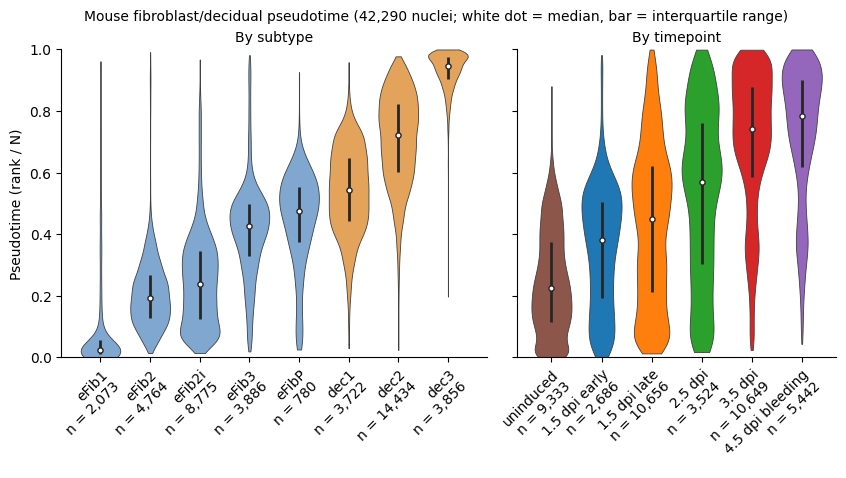

In [13]:
# Violin plots of the rank-normalized pseudotime, by subtype and by timepoint.
# Nuclei without a pseudotime (the 907 decAp) are left out.
# For coarse cell types instead of subtypes, set GROUP_COL = "cell_type" (groups are then ordered by median pseudotime).
import matplotlib.pyplot as plt

GROUP_COL = LABEL_COL                       # "cell_subtype"

cells = out.obs.loc[out.obs["pseudotime"].notna(), ["pseudotime", GROUP_COL, "timepoint"]].astype(
    {GROUP_COL: str, "timepoint": str})
group_order = ORDER if GROUP_COL == LABEL_COL else list(
    cells.groupby(GROUP_COL)["pseudotime"].median().sort_values().index)
timepoint_order = sorted(DAY, key=DAY.get)

# Timepoint colors from the object when it carries them (scanpy stores them in category order)
tp_categories = list(out.obs["timepoint"].cat.categories) if hasattr(out.obs["timepoint"], "cat") else []
tp_colors = dict(zip(tp_categories, out.uns.get("timepoint_colors", [])))
FIB_COLOR, DEC_COLOR, OTHER_COLOR = "#7fa7cf", "#e3a35b", "#bdbdbd"


def group_color(group):
    if group.lower().startswith(("efib", "endometrial_fib", "fib")):
        return FIB_COLOR
    if group.lower().startswith(("dec", "decidual")):
        return DEC_COLOR
    return OTHER_COLOR


def draw_violins(ax, column, order, colors):
    values = [cells.loc[cells[column] == group, "pseudotime"].to_numpy() for group in order]
    positions = np.arange(1, len(order) + 1)
    parts = ax.violinplot(values, positions=positions, widths=0.8, showextrema=False)
    for body, color in zip(parts["bodies"], colors):
        body.set_facecolor(color)
        body.set_edgecolor("0.25")
        body.set_linewidth(0.6)
        body.set_alpha(1)
    quartiles = np.array([np.percentile(v, [25, 50, 75]) for v in values])
    ax.vlines(positions, quartiles[:, 0], quartiles[:, 2], color="0.15", linewidth=2)
    ax.scatter(positions, quartiles[:, 1], color="white", edgecolor="0.15", s=14, zorder=3)
    labels = [f"{group.replace('_', ' ')}\nn = {len(v):,}" for group, v in zip(order, values)]
    ax.set_xticks(positions, labels, rotation=45, ha="right", rotation_mode="anchor")
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True,
                         gridspec_kw={"width_ratios": [len(group_order), len(timepoint_order)], "wspace": 0.08})
draw_violins(axes[0], GROUP_COL, group_order, [group_color(g) for g in group_order])
draw_violins(axes[1], "timepoint", timepoint_order, [tp_colors.get(t, OTHER_COLOR) for t in timepoint_order])
axes[0].set_title("By subtype" if GROUP_COL == LABEL_COL else "By cell type", fontsize=10)
axes[1].set_title("By timepoint", fontsize=10)
axes[0].set_ylabel("Pseudotime (rank / N)")
axes[0].set_ylim(0, 1)
fig.suptitle(f"Mouse fibroblast/decidual pseudotime ({len(cells):,} nuclei; white dot = median, bar = interquartile range)",
             fontsize=10)
fig.tight_layout()
plt.show()

In [70]:
out = obj.copy()
pseudotime = pd.Series(np.nan, index=out.obs_names)
pseudotime[a.obs_names] = pt_rank
out.obs["pseudotime"] = pseudotime.to_numpy()
diffmap = np.full((out.n_obs, DM.shape[1]), np.nan)
diffmap[keep] = DM
out.obsm["X_diffmap"] = diffmap

out.uns["pseudotime"] = dict(
    description="Harmonized time-informed diffusion pseudotime (moscot couplings, CellRank RealTimeKernel, "
                "symmetrized diffusion map, DPT), rank-normalized as average rank / N; see Methods, Pseudotime.",
    root=str(a.obs_names[root]), root_label=str(lab.iloc[root]), trajectory_dc=int(best), n_cells=int(a.n_obs),
    n_dcs=P["n_dcs"], params={k: str(v) for k, v in P.items()}, latent=latent_source,
    diffmap_evals=np.asarray(a.uns["diffmap_evals"], dtype=float), transition_mass={k: float(v) for k, v in mass.items()},
    input_object=INPUT_OBJECT, input_sha256=input_sha256, versions=versions,
    computed=datetime.datetime.now().isoformat(timespec="seconds"))

IndexError: boolean index did not match indexed array along axis 0; size of axis is 41811 but size of corresponding boolean axis is 4102

In [12]:
os.makedirs(os.path.dirname(OUTPUT_OBJECT), exist_ok=True)
out.write_h5ad(OUTPUT_OBJECT, compression="gzip")
print(f"wrote {OUTPUT_OBJECT} ({out.n_obs:,} nuclei; {int(out.obs['pseudotime'].notna().sum()):,} with pseudotime) "
      f"in {time.time() - t_start:.0f} s")

Exception ignored in: <function WeakValueDictionary.__init__.<locals>.remove at 0x1505fd42d1c0>
Traceback (most recent call last):
  File "/n/home12/nhilgert/.local/share/uv/python/cpython-3.11.15-linux-x86_64-gnu/lib/python3.11/weakref.py", line 105, in remove
    def remove(wr, selfref=ref(self), _atomic_removal=_remove_dead_weakref):

KeyboardInterrupt: 


wrote /n/netscratch/eddy_lab/Everyone/nhilgert/2026_11_06_pseudotime_notebooks/Cevrim_XMens_Only_Fib_Dec_Cells_pseudotime.h5ad (43,197 nuclei; 42,290 with pseudotime) in 304 s


## Comparison with the pseudotime of record

The input object's `obs['pseudotime']` and `obsm['X_diffmap']` are the runs of record. On the same software, the mouse computation has reproduced them exactly on Intel nodes with 8 CPUs, and to within 4 × 10⁻⁵ in rank pseudotime on an AMD node. The human run of record was computed on one particular node (holygpu7c0530: Intel Cascade Lake, 16 CPUs, JAX on CPU), and human reruns on other nodes have differed slightly through the order of floating-point additions: same root, ρ ≈ 0.999 with the record, and no reported number changed. A latent refit on a GPU other than an A40 will differ more. The numbers below show which case applies.

In [ ]:
if stored_pseudotime is None:
    print("The input object has no pseudotime to compare with.")
else:
    old = stored_pseudotime.to_numpy(float)
    new = out.obs["pseudotime"].to_numpy(float)
    same_nan = bool(np.array_equal(np.isnan(old), np.isnan(new)))
    both = ~np.isnan(old) & ~np.isnan(new)
    diff = np.abs(new[both] - old[both])
    dm_old, dm_new = stored_diffmap[both], out.obsm["X_diffmap"][both]
    print(f"nuclei without pseudotime: same set {same_nan} ({int(np.isnan(new).sum())})")
    print(f"pseudotime identical to the record: {bool(np.array_equal(new[both], old[both]))}")
    print(f"  Spearman rho with the record {spearmanr(new[both], old[both]).statistic:.6f}; |difference| median "
          f"{np.median(diff):.2e}, 99th percentile {np.quantile(diff, 0.99):.2e}, largest {diff.max():.2e}; "
          f"nuclei moved by more than 0.05: {int((diff > 0.05).sum())}")
    print(f"diffusion map identical to the record: {bool(np.array_equal(dm_new, dm_old))} "
          f"(largest difference {np.nanmax(np.abs(dm_new - dm_old)):.2e})")
    print(f"root: {out.uns['pseudotime']['root']} (Methods: {RECORD_ROOT}); same {out.uns['pseudotime']['root'] == RECORD_ROOT}")